In [2]:
import scimap as sm

Running SCIMAP  2.3.4


In [3]:
import os
os.getcwd()

'C:\\Users\\tpeng\\Documents\\Spatial\\notebook'

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import anndata as ad
import scanpy as sc

## pt4_lesion ##

In [51]:
adata = sc.read ('C:\\Users\\tpeng\\\Documents\\Spatial\\adata_files\\Xenium_Proseq_pt4_lesion_neighborhood_261009.h5ad')
adata

AnnData object with n_obs × n_vars = 8286 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3', 'imageid', 'spatial_lda_kmeans6'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'spatial_lda', 'spatial_lda_probability', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [29]:
# run the LDA tool
adata = sm.tl.spatial_lda(adata, phenotype='Cell_label_L3', method='radius', radius=80, label='spatial_lda')

Processing: ['DDlesion_proseq']
Identifying neighbours within 80 pixels of every cell
Pre-Processing Spatial LDA
Training Spatial LDA
Calculating the Coherence Score

Coherence Score:  0.22500577639230102
Gathering the latent weights


C:\Users\tpeng\anaconda3\envs\scimap\lib\site-packages\scimap\tools\spatial_lda.py:270: ImplicitModificationWarning:

Trying to modify attribute `._uns` of view, initializing view as actual.



In [30]:
adata

AnnData object with n_obs × n_vars = 8286 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'SampleID', 'Tissue_type', 'PatientID', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3', 'imageid'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap', 'spatial_lda', 'spatial_lda_probability'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [33]:
adata = sm.tl.spatial_cluster(adata, df_name='spatial_lda', method='kmeans', k=6, label='spatial_lda_kmeans6')
adata

Kmeans clustering


AnnData object with n_obs × n_vars = 8286 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'SampleID', 'Tissue_type', 'PatientID', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3', 'imageid', 'spatial_lda_kmeans6'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap', 'spatial_lda', 'spatial_lda_probability'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [35]:
# Let's visualize the results.

from matplotlib import rcParams
FIGSIZE = (16, 16)
my_colors = {'0':'plum', '1':'olive', '2':'yellowgreen', '3':'MediumPurple', '4':'lightsteelblue','5' : 'lightsalmon'}

sm.pl.spatial_scatterPlot(adata, colorBy='spatial_lda_kmeans6', s =4, alpha = 0.8,  dpi = 300,customColors = my_colors,
                          fileName='scatterplot_pt4_lesion_IC+kera_6clusters_261009.png', saveDir="./figures")

Saved plot to ./figures\scatterplot_pt4_lesion_IC+kera_6clusters_261009.png


In [37]:
adata

AnnData object with n_obs × n_vars = 8286 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'SampleID', 'Tissue_type', 'PatientID', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3', 'imageid', 'spatial_lda_kmeans6'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap', 'spatial_lda', 'spatial_lda_probability'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [49]:
adata.obs.imageid.unique()

['Pt4_lesion_proseq']
Categories (1, object): ['Pt4_lesion_proseq']

In [45]:
adata.obs['imageid'] = 'Pt4_lesion_proseq'

In [47]:
adata.write_h5ad ('C:\\Users\\tpeng\\\Documents\\Spatial\\adata_files\\Xenium_Proseq_pt4_lesion_neighborhood_261009.h5ad')

## Generate heatmap ##

In [2]:
adata = sc.read ('C:\\Users\\tpeng\\adata_files\\Xenium_Proseq_pt4_lesion_neighborhood_261009.h5ad')
adata

AnnData object with n_obs × n_vars = 8286 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcodes', 'leiden', 'Cell_label_L3', 'imageid', 'spatial_lda_kmeans6'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'spatial_lda', 'spatial_lda_probability', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [3]:
df = adata.obs.groupby("Cell_label_L3")["spatial_lda_kmeans6"].value_counts().unstack()
df

C:\Users\tpeng\AppData\Local\Temp\ipykernel_16592\545790267.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = adata.obs.groupby("Cell_label_L3")["spatial_lda_kmeans6"].value_counts().unstack()


spatial_lda_kmeans6,0,1,2,3,4,5
Cell_label_L3,,,,,,
B cell,27,0,3,3,28,4
Basal keratinocyte_non-lesion,0,100,552,10,19,10
CD4 T cell_FOXP3+,118,1,17,4,278,51
CD4 T cell_GZMBhi,52,1,13,4,105,8
CD4 T cell_GZMBlow,599,0,16,4,350,38
CD8 T cell_GZMBhi,43,1,5,4,97,3
CD8 T cell_GZMBlow,341,3,64,9,476,42
DC,89,0,7,0,93,27
DC_LAMP3+,143,1,7,7,273,24


In [4]:
frequency_table = (df / df.sum())*100
pd.options.display.float_format = '{:.2f}'.format

In [5]:
# Define your desired custom order
custom_order = ['3', '5', '0','1','2','4']
frequency_table = frequency_table[custom_order]
frequency_table.columns = ['N0','N1','N2','N3','N4','N5']
frequency_table.head(n=2)

,N0,N1,N2,N3,N4,N5
Cell_label_L3,,,,,,
B cell,0.31,0.62,1.30,0.00,0.25,0.98
Basal keratinocyte_non-lesion,1.03,1.55,0.00,18.38,46.27,0.66


In [6]:
# Replace specific elements using a dictionary
frequency_table.index = frequency_table.index.rename_categories({
                                                       'Supra keratinocyte_CXCL8+': 'Spinosum keratinocyte_CXCL8+',
                                                       'Supra keratinocyte_KRT2+_2': 'Granulosum keratinocyte_KRT2+',
                                                       'Supra keratinocyte_KRT2+_1': 'Spinosum keratinocyte_KRT2+',
                                                       'Basal keratinocyte_non-lesion' : 'Basal keratinocyte_adj'})
frequency_table

,N0,N1,N2,N3,N4,N5
Cell_label_L3,,,,,,
B cell,0.31,0.62,1.30,0.00,0.25,0.98
Basal keratinocyte_adj,1.03,1.55,0.00,18.38,46.27,0.66
CD4 T cell_FOXP3+,0.41,7.91,5.68,0.18,1.42,9.72
CD4 T cell_GZMBhi,0.41,1.24,2.50,0.18,1.09,3.67
CD4 T cell_GZMBlow,0.41,5.89,28.85,0.00,1.34,12.23
CD8 T cell_GZMBhi,0.41,0.47,2.07,0.18,0.42,3.39
CD8 T cell_GZMBlow,0.93,6.51,16.43,0.55,5.36,16.64
DC,0.00,4.19,4.29,0.00,0.59,3.25
DC_LAMP3+,0.72,3.72,6.89,0.18,0.59,9.54


In [7]:
list2 = ['Spinosum keratinocyte_CXCL8+',
         'Granulosum keratinocyte_KRT2+',
         'Spinosum keratinocyte_KRT2+',
         'Basal keratinocyte_adj',
         'CD8 T cell_GZMBhi',
         'CD4 T cell_GZMBhi',
         'CD8 T cell_GZMBlow',
         'CD4 T cell_GZMBlow',
         'CD4 T cell_FOXP3+',
         'NK cell',
         'B cell', 'Plasmablast cell',
         'Mono_ISGhi','Mono_ISGlow',
         'Mac_ISGlow', 'Mast cell',
         'DC_LAMP3+','DC',
         'PDC']

In [8]:
# Define your desired custom order
custom_order = list2
# Reorder the index based on the list
frequency_table = frequency_table.reindex(custom_order)
frequency_table

,N0,N1,N2,N3,N4,N5
Cell_label_L3,,,,,,
Spinosum keratinocyte_CXCL8+,0.10,0.16,0.00,0.92,14.42,0.00
Granulosum keratinocyte_KRT2+,0.00,0.00,0.00,11.58,0.00,0.00
Spinosum keratinocyte_KRT2+,0.00,0.00,0.00,63.79,4.69,0.00
Basal keratinocyte_adj,1.03,1.55,0.00,18.38,46.27,0.66
CD8 T cell_GZMBhi,0.41,0.47,2.07,0.18,0.42,3.39
CD4 T cell_GZMBhi,0.41,1.24,2.50,0.18,1.09,3.67
CD8 T cell_GZMBlow,0.93,6.51,16.43,0.55,5.36,16.64
CD4 T cell_GZMBlow,0.41,5.89,28.85,0.00,1.34,12.23
CD4 T cell_FOXP3+,0.41,7.91,5.68,0.18,1.42,9.72


In [9]:
frequency_table.index = [
 'Spino kera_CXCL8+',
 'Granu kera_KRT2+',
 'Spino kera_KRT2+',
 'Basa kera_adj',
 'CD8 T_GZMBhi','CD4 T_GZMBhi',
 'CD8 T_GZMBlow','CD4 T_GZMBlow','CD4 T_FOXP3+',
 'NK','B','Plasmablast',
 'Mono_ISGhi','Mono_ISGlow','Mac_ISGlow','Mast',
 'DC_LAMP3+',
 'DC',
 'PDC']
frequency_table

,N0,N1,N2,N3,N4,N5
Spino kera_CXCL8+,0.10,0.16,0.00,0.92,14.42,0.00
Granu kera_KRT2+,0.00,0.00,0.00,11.58,0.00,0.00
Spino kera_KRT2+,0.00,0.00,0.00,63.79,4.69,0.00
Basa kera_adj,1.03,1.55,0.00,18.38,46.27,0.66
CD8 T_GZMBhi,0.41,0.47,2.07,0.18,0.42,3.39
CD4 T_GZMBhi,0.41,1.24,2.50,0.18,1.09,3.67
CD8 T_GZMBlow,0.93,6.51,16.43,0.55,5.36,16.64
CD4 T_GZMBlow,0.41,5.89,28.85,0.00,1.34,12.23
CD4 T_FOXP3+,0.41,7.91,5.68,0.18,1.42,9.72
NK,1.86,3.57,4.58,0.55,1.42,6.19


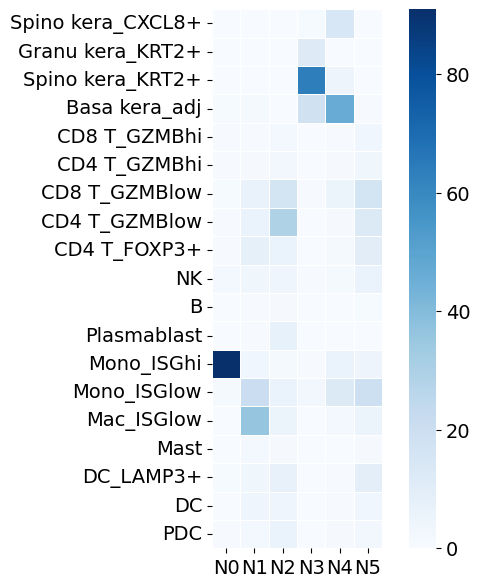

In [10]:
plt.figure(figsize=(7, 7)) # Optional: Adjust the size of the plot

ax = sns.heatmap(
    data= frequency_table,          # The DataFrame/data to plot
    annot=False,               # Display the correlation values on the heatmap
    cmap='Blues',          # The color map (e.g., 'viridis', 'plasma', 'coolwarm')
    fmt=".2f",                # String format for annotation values
    linewidths=.5,            # Space between cells
    annot_kws={"fontsize": 16}, square = True
)


# Set the font size for the x and y tick labels
ax.set_xticklabels(ax.get_xticklabels(), fontsize=14)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=14)


# Access the colorbar and set the size of its tick labels
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=14) # 'labelsize' parameter sets the tick label font size

plt.show()

In [11]:
adata.obs.imageid.unique()

['Pt4_lesion_proseq']
Categories (1, object): ['Pt4_lesion_proseq']